## Delhi Air Quality Cleaning: PM2.5 and NO2 (March-November 2025)

**Prepared by:** Yashvi Patel

This notebook prepares and checks the hourly Delhi PM2.5 and NO2 data, studies missing observations, creates a daily dataset, and examines possible outliers. The analysis retains the original hourly values and clearly separates measured data from estimated values.

### 1. Setup and load files


In [125]:
%pip install missingno

Note: you may need to restart the kernel to use updated packages.


In [126]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import missingno as msno
from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [127]:
required_input = Path("data/raw/air_quality/pm25_hourly_mar_nov.csv")
root_candidates = [Path.cwd(), *Path.cwd().parents]
root_candidates += [candidate / "EDA-Group-Project" for candidate in root_candidates]

PROJECT_ROOT = next(
    (candidate for candidate in root_candidates if (candidate / required_input).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find {required_input} from {Path.cwd()}. "
        "Start Jupyter in the project or notebooks directory."
    )

RAW_DIR = PROJECT_ROOT / "data/raw/air_quality"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
DAILY_PATH = PROCESSED_DIR / "pollution_daily.csv"
print("Project directory:", PROJECT_ROOT)

Project directory: c:\Users\YASHVI PATEL\Documents\Study Only\EDA\EDA-PROJECT\EDA-Group-Project


### 2. Inspect both hourly files

`datetime_from_local` records Delhi local time with an offset such as `+05:30`. Parsing only the first 19 characters intentionally removes the offset while keeping the local clock reading as a naive timestamp. Source rows are sorted and duplicate timestamps are rejected, because duplicates would double-count hours during aggregation.

In [128]:
def load_hourly(fname):
    path = RAW_DIR / fname
    try:
        df = pd.read_csv(path)
    except FileNotFoundError:
        print("missing file:", path)
        raise

    required_columns = {"datetime_from_local", "value", "sensor_id", "unit"}
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(f"{fname} is missing columns: {sorted(missing_columns)}")

    df["time"] = pd.to_datetime(df["datetime_from_local"].str[:19], errors="raise")
    df["value"] = pd.to_numeric(df["value"], errors="raise")
    if df["time"].duplicated().any():
        raise ValueError(f"Duplicate timestamps found in {fname}")
    return df.sort_values("time").reset_index(drop=True)

In [129]:
pm_raw = load_hourly("pm25_hourly_mar_nov.csv")
no2_raw = load_hourly("no2_hourly_mar_nov.csv")
print("PM2.5 shape:", pm_raw.shape)
print("NO2 shape:", no2_raw.shape)

PM2.5 shape: (5914, 9)
NO2 shape: (5985, 9)


### 2.1 First look at both datasets

Review the dimensions, data types, descriptive statistics, duplicate timestamp count, sensor and unit metadata, skewness, and kurtosis. The shape and missing reading checks are performed on the raw files before expanding them to a complete hourly calendar.

In [130]:
for name, df in [("PM2.5", pm_raw), ("NO2", no2_raw)]:
    print("\n=====", name, "shape:", df.shape)
    df.info()
    display(df.describe())
    print("duplicate timestamps:", df["time"].duplicated().sum())
    print("sensor ids:", df["sensor_id"].unique(), "| units:", df["unit"].unique())
    print("skew:", round(df["value"].skew(), 2), "| kurtosis:", round(df["value"].kurt(), 2))
    print("explicit null readings:", df["value"].isna().sum())


===== PM2.5 shape: (5914, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5914 entries, 0 to 5913
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   sensor_id            5914 non-null   int64         
 1   parameter            5914 non-null   object        
 2   value                5910 non-null   float64       
 3   unit                 5914 non-null   object        
 4   datetime_from_utc    5914 non-null   object        
 5   datetime_to_utc      5914 non-null   object        
 6   datetime_from_local  5914 non-null   object        
 7   datetime_to_local    5914 non-null   object        
 8   time                 5914 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 416.0+ KB


,sensor_id,value,time
count,5914.0,5910.000000,5914
mean,12235312.0,59.430553,2025-07-19 04:18:46.141359616
min,12235312.0,1.000000,2025-03-01 05:00:00
25%,12235312.0,23.500000,2025-05-09 15:15:00
50%,12235312.0,41.000000,2025-07-21 23:30:00
75%,12235312.0,68.950000,2025-09-25 03:45:00
max,12235312.0,968.000000,2025-12-01 04:00:00
std,0.0,62.188346,NaN


duplicate timestamps: 0
sensor ids: [12235312] | units: ['µg/m³']
skew: 3.64 | kurtosis: 24.63
explicit null readings: 4

===== NO2 shape: (5985, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5985 entries, 0 to 5984
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   sensor_id            5985 non-null   int64         
 1   parameter            5985 non-null   object        
 2   value                5985 non-null   float64       
 3   unit                 5985 non-null   object        
 4   datetime_from_utc    5985 non-null   object        
 5   datetime_to_utc      5985 non-null   object        
 6   datetime_from_local  5985 non-null   object        
 7   datetime_to_local    5985 non-null   object        
 8   time                 5985 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 420.9+ KB


,sensor_id,value,time
count,5985.0,5985.000000,5985
mean,12235309.0,26.198172,2025-07-17 14:57:19.398496256
min,12235309.0,0.000000,2025-03-01 05:00:00
25%,12235309.0,13.800000,2025-05-07 02:00:00
50%,12235309.0,21.300000,2025-07-20 03:00:00
75%,12235309.0,34.100000,2025-09-24 03:00:00
max,12235309.0,131.000000,2025-12-01 04:00:00
std,0.0,17.758976,NaN


duplicate timestamps: 0
sensor ids: [12235309] | units: ['ppb']
skew: 1.54 | kurtosis: 3.13
explicit null readings: 0


## 3. Build the complete hourly calendar

The source exports can omit timestamps entirely. Reindexing with `.asfreq("h")` makes each absent hour visible as `NaN`. The inclusive local-time calendar runs from **2025-03-01 05:00:00** through **2025-12-01 04:00:00**, which is 6,600 hours. The December 1 endpoint reflects the local start time of the hourly sensor windows; the daily output is restricted to March 1 through November 30.

In [131]:
pm = pm_raw.set_index("time")["value"].sort_index().asfreq("h")
no2 = no2_raw.set_index("time")["value"].sort_index().asfreq("h")

print("range:", pm.index.min(), "->", pm.index.max(), "| total hours:", len(pm))
for name, series in [("PM2.5", pm), ("NO2", no2)]:
    print(name, "missing hours:", series.isna().sum(), f"({series.isna().mean() * 100:.1f}%)")

range: 2025-03-01 05:00:00 -> 2025-12-01 04:00:00 | total hours: 6600
PM2.5 missing hours: 690 (10.5%)
NO2 missing hours: 615 (9.3%)


### 3.1 Separate absent timestamps from explicit nulls

An absent timestamp is different from a row that exists but has a null `value`. PM2.5 has four explicit null readings on October 21 during the Diwali pollution episode. These four are part of the 690 total missing PM2.5 calendar hours. NO2 has no explicit-null rows; its missing calendar hours are absent timestamps.

In [132]:
pm_nulls = pm_raw["value"].isna().sum()
no2_nulls = no2_raw["value"].isna().sum()

print("PM2.5 rows present but empty:", pm_nulls)
print("PM2.5 rows absent from file:", pm.isna().sum() - pm_nulls)
print(pm_raw.loc[pm_raw["value"].isna(), "time"].tolist())
print("NO2 rows present but empty:", no2_nulls)
print("NO2 rows absent from file:", no2.isna().sum() - no2_nulls)

PM2.5 rows present but empty: 4
PM2.5 rows absent from file: 686
[Timestamp('2025-10-21 02:00:00'), Timestamp('2025-10-21 03:00:00'), Timestamp('2025-10-21 04:00:00'), Timestamp('2025-10-21 05:00:00')]
NO2 rows present but empty: 0
NO2 rows absent from file: 615


### 3.2 Check the hourly calendar

These checks confirm the expected source row counts, full hourly-calendar size and bounds, missing reading counts, duplicate handling, and explicit PM2.5 null timestamps. If the input data changes, the notebook stops here and makes the difference visible.

In [133]:
START = pd.Timestamp("2025-03-01 05:00:00")
END = pd.Timestamp("2025-12-01 04:00:00")

assert len(pm_raw) == 5_914
assert len(no2_raw) == 5_985
assert len(pm) == len(no2) == 6_600
assert pm.isna().sum() == 690
assert no2.isna().sum() == 615
assert pm.index.min() == START and pm.index.max() == END
assert no2.index.min() == START and no2.index.max() == END
assert pm_raw["time"].is_unique and no2_raw["time"].is_unique
assert pm_nulls == 4 and no2_nulls == 0
assert pm_raw.loc[pm_raw["value"].isna(), "time"].dt.date.nunique() == 1
assert pm_raw.loc[pm_raw["value"].isna(), "time"].dt.strftime("%Y-%m-%d").eq("2025-10-21").all()
print("Hourly data checks passed.")

Hourly data checks passed.


## 4. Missing data: gap lengths and overlap

The number of missing hours alone does not distinguish isolated short gaps from long outages. Consecutive missing hours are grouped into runs so that gaps suitable for short interpolation can be separated from longer gaps. Comparing PM2.5 and NO2 missingness at matching timestamps helps assess whether gaps are common to both series or pollutant-specific; coincident gaps are suggestive of station-wide downtime, not proof of cause.

The chi-square test used later compares observed and expected missingness counts:

$$\chi^2 = \sum \frac{(O_{ij}-E_{ij})^2}{E_{ij}}$$

In [134]:
def missing_gap_table(series):
    """Return start, end, and duration for each consecutive missing run."""
    missing = series.isna()
    group_id = missing.ne(missing.shift(fill_value=False)).cumsum()
    records = []
    for _, run in series[missing].groupby(group_id[missing]):
        records.append({"start": run.index[0], "end": run.index[-1], "hours": len(run)})
    return pd.DataFrame(records, columns=["start", "end", "hours"])

In [135]:
pm_gaps = missing_gap_table(pm)
no2_gaps = missing_gap_table(no2)

for name, gaps in [("PM2.5", pm_gaps), ("NO2", no2_gaps)]:
    print("\n", name, "number of gaps:", len(gaps))
    print("longest gap:", gaps["hours"].max(), "hours")
    print("gap counts by length:")
    display(gaps["hours"].value_counts().sort_index().rename("number of gaps"))
    print("gaps up to 6 hours:", gaps["hours"].le(6).sum())
    print("hours in gaps up to 6 hours:", gaps.loc[gaps["hours"].le(6), "hours"].sum())


 PM2.5 number of gaps: 94
longest gap: 60 hours
gap counts by length:


hours
1     38
2     15
3      1
4      4
5      5
6      3
8      1
9      3
10     3
11     1
12     1
13     2
14     3
15     1
16     1
17     3
19     1
20     1
22     1
26     1
32     1
36     1
47     1
60     2
Name: number of gaps, dtype: int64

gaps up to 6 hours: 66
hours in gaps up to 6 hours: 130

 NO2 number of gaps: 98
longest gap: 60 hours
gap counts by length:


hours
1     40
2     18
3      5
4      3
5      4
6      3
8      1
9      3
10     2
11     3
12     1
13     2
14     3
15     1
16     2
19     1
20     1
21     1
32     1
47     1
60     2
Name: number of gaps, dtype: int64

gaps up to 6 hours: 73
hours in gaps up to 6 hours: 141


In [136]:
assert len(pm_gaps) == 94
assert pm_gaps["hours"].max() == 60
assert pm_gaps["hours"].eq(1).sum() == 38
assert pm_gaps["hours"].between(2, 6).sum() == 28
assert pm_gaps["hours"].gt(6).sum() == 28
assert len(no2_gaps) == 98 and no2_gaps["hours"].max() == 60
print("Gap-length checks passed.")

Gap-length checks passed.


In [137]:
pm_missing = pm.isna()
no2_missing = no2.isna()

missing_pattern = pd.Series(
    np.select(
        [pm_missing & no2_missing, pm_missing, no2_missing],
        ["both missing", "PM2.5 only", "NO2 only"],
        default="neither missing",
    ),
    index=pm.index,
    name="missingness pattern",
)
print("Missing-hour overlap:")
display(missing_pattern.value_counts().rename_axis("pattern").to_frame("hours"))

Missing-hour overlap:


,hours
pattern,
neither missing,5869
both missing,574
PM2.5 only,116
NO2 only,41


In [138]:
overlap_counts = missing_pattern.value_counts()
print("Both missing:", overlap_counts["both missing"])
print("PM2.5 only:", overlap_counts["PM2.5 only"])
print("NO2 only:", overlap_counts["NO2 only"])
assert overlap_counts["both missing"] == 574
assert overlap_counts["PM2.5 only"] == 116
assert overlap_counts["NO2 only"] == 41

Both missing: 574
PM2.5 only: 116
NO2 only: 41


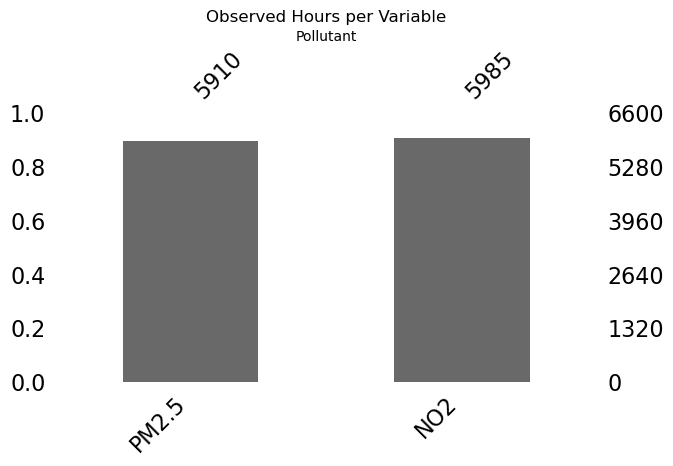

In [139]:
df_combined = pd.DataFrame({"PM2.5": pm, "NO2": no2})
msno.bar(df_combined, figsize=(7, 3.5))
plt.title("Observed Hours per Variable")
plt.xlabel("Pollutant")
plt.ylabel("Observed hourly readings (hours)")
plt.show()

**Observation:** PM2.5 has 5,910 observed hours and NO2 has 5,985, out of 6,600 calendar hours. PM2.5 therefore has more missing readings in this period.

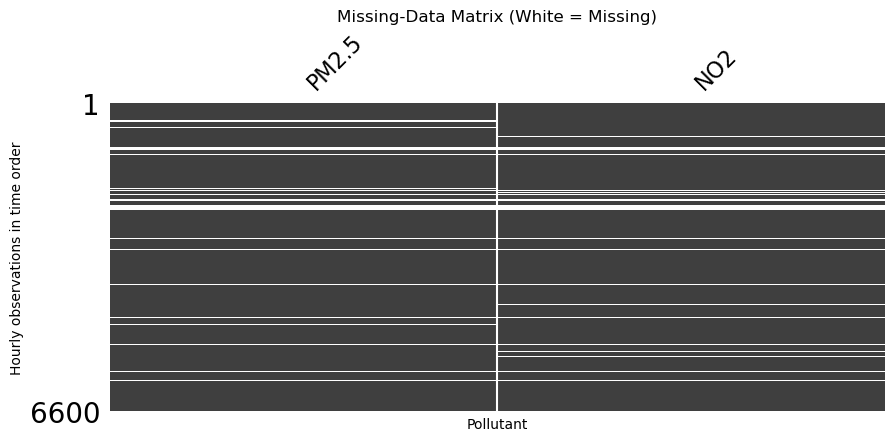

In [140]:
msno.matrix(df_combined, figsize=(10, 4), sparkline=False)
plt.title("Missing-Data Matrix (White = Missing)")
plt.xlabel("Pollutant")
plt.ylabel("Hourly observations in time order")
plt.show()

**Observation:** The white sections mark missing readings, and some gaps line up across both pollutants. The longest single-pollutant gaps last 60 hours, including outages in April and June.

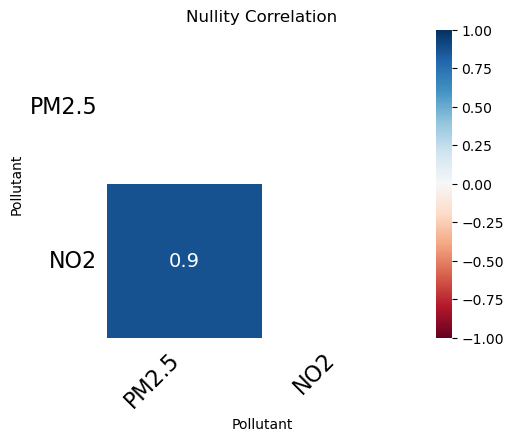

In [141]:
msno.heatmap(df_combined, figsize=(5, 4))
plt.title("Nullity Correlation")
plt.xlabel("Pollutant")
plt.ylabel("Pollutant")
plt.show()

**Observation:** The missingness correlation between PM2.5 and NO2 is 0.87, so the two pollutants tend to go missing in the same hours. 574 of the 690 missing PM2.5 hours are also missing NO2, which fits station-wide outages.

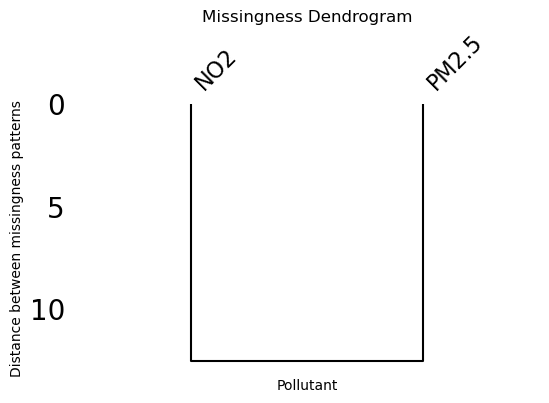

In [142]:
msno.dendrogram(df_combined, figsize=(6, 3.5))
plt.title("Missingness Dendrogram")
plt.xlabel("Pollutant")
plt.ylabel("Distance between missingness patterns")
plt.show()

**Observation:** With only two variables the dendrogram always joins them into one cluster, so it adds little here. The 0.87 correlation and the overlap counts carry the evidence.

### 4.1 Missingness by month

Monthly missing-hour percentages and a chi-square test compare missing versus observed hours across months. A small p-value is evidence that missingness changes by month, so missingness is not independent of calendar month (and the MCAR assumption is questionable). This association alone does not establish a specific missing-at-random mechanism.

In [143]:
monthly_missing = pd.DataFrame({"PM2.5": pm_missing, "NO2": no2_missing}).resample("MS").mean()
monthly_missing = monthly_missing.loc[monthly_missing.index.month <= 11]
display((monthly_missing * 100).round(2).rename_axis("month"))

,PM2.5,NO2
month,,
2025-03-01,11.10,0.14
2025-04-01,14.72,15.00
2025-05-01,16.13,15.99
2025-06-01,17.22,19.17
2025-07-01,5.38,5.24
2025-08-01,7.53,8.06
2025-09-01,6.39,4.44
2025-10-01,9.01,9.27
2025-11-01,6.81,6.81


In [144]:
missingness_test_rows = []
for name, series in [("PM2.5", pm), ("NO2", no2)]:
    study_series = series.loc[:"2025-11-30 23:00:00"]
    for grouping_name, grouping in [
        ("month", study_series.index.month),
        ("hour of day", study_series.index.hour),
    ]:
        table = pd.crosstab(grouping, study_series.isna())
        statistic, p_value, degrees_freedom, _ = chi2_contingency(table)
        missingness_test_rows.append(
            {
                "series": name,
                "grouped by": grouping_name,
                "chi-square": statistic,
                "degrees of freedom": degrees_freedom,
                "p-value": p_value,
            }
        )
missingness_tests = pd.DataFrame(missingness_test_rows)
display(missingness_tests.style.format({"chi-square": "{:.1f}", "p-value": "{:.2e}"}))

,series,grouped by,chi-square,degrees of freedom,p-value
0,PM2.5,month,127.0,8,1.19e-23
1,PM2.5,hour of day,15.7,23,8.67e-01
2,NO2,month,264.6,8,1.38e-52
3,NO2,hour of day,14.3,23,9.19e-01


**Observation:** PM2.5 missingness changes by month (p = 1.19e-23) but shows no evidence of an hour-of-day pattern (p = 0.87). NO2 missingness also varies by month (p = 1.38e-52), while its hour-of-day test is not significant (p = 0.92).

### 4.2 Compare missingness over time

The upper panel shows monthly missing percentages; the lower panel compares the daily number of missing hours in the two sensors. Overlapping periods support a station-wide downtime hypothesis, while unmatched missing hours may reflect sensor-specific data loss.

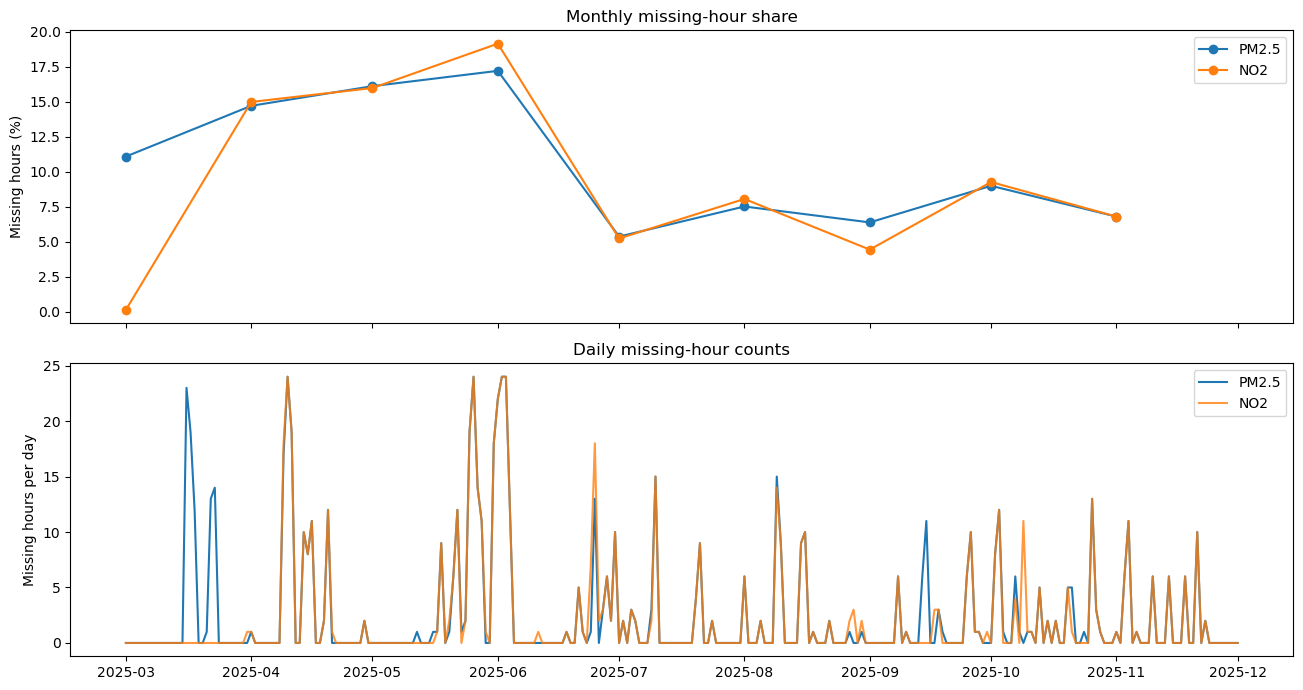

In [145]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(monthly_missing.index, monthly_missing["PM2.5"] * 100, marker="o", label="PM2.5")
axes[0].plot(monthly_missing.index, monthly_missing["NO2"] * 100, marker="o", label="NO2")
axes[0].set_ylabel("Missing hours (%)")
axes[0].set_title("Monthly missing-hour share")
axes[0].legend()

axes[1].plot(pm_missing.resample("D").sum(), label="PM2.5")
axes[1].plot(no2_missing.resample("D").sum(), label="NO2", alpha=0.8)
axes[1].set_ylabel("Missing hours per day")
axes[1].set_title("Daily missing-hour counts")
axes[1].legend()
fig.tight_layout()
plt.show()

**Observation:** PM2.5 missingness is highest in June (17.2%) and falls to 5.4% in July. March is different: PM2.5 has 11.1% missingness while NO2 has about 0.1%, suggesting some gaps are sensor-specific.

## 5. Compare missing-value treatments

Time interpolation is used only for internal missing runs of six hours or less. Longer gaps are not bridged by interpolation. To assess longer outages, the validation below masks 30 separated 20-hour blocks where both pollutants were originally observed, then compares a global mean, a month-by-hour baseline, KNN, and MICE with three random seeds. Block MAE and RMSE are measured against the held-out PM2.5 values; estimated values are not observations.

$$\text{MAE}=\frac{1}{n}\sum|\hat y_i-y_i|, \qquad \text{RMSE}=\sqrt{\frac{1}{n}\sum(\hat y_i-y_i)^2}$$

In [146]:
def interpolate_short_gaps(series, max_gap=6):
    """Time-interpolate only internal missing runs no longer than max_gap."""
    gaps = missing_gap_table(series)
    result = series.copy()
    interpolated = series.interpolate(method="time", limit_area="inside")
    for gap in gaps.loc[gaps["hours"].le(max_gap)].itertuples(index=False):
        result.loc[gap.start:gap.end] = interpolated.loc[gap.start:gap.end]
    return result

In [147]:
def imputation_features(pm_values, no2_values):
    """Combine pollutant values with cyclical local-time features."""
    index = pm_values.index
    hour_angle = 2 * np.pi * index.hour / 24
    year_angle = 2 * np.pi * index.dayofyear / 365.25
    return pd.DataFrame(
        {
            "pm25": pm_values.to_numpy(dtype=float),
            "no2": no2_values.reindex(index).to_numpy(dtype=float),
            "hour_sin": np.sin(hour_angle),
            "hour_cos": np.cos(hour_angle),
            "year_sin": np.sin(year_angle),
            "year_cos": np.cos(year_angle),
        },
        index=index,
    )

In [148]:
def multivariate_pm_imputation(pm_values, no2_values, method, seed=RANDOM_STATE):
    """Estimate PM2.5 using scaled KNN or stochastic iterative imputation."""
    features = imputation_features(pm_values, no2_values)
    scaler = StandardScaler()
    scaled = scaler.fit_transform(features)

    if method == "KNN":
        imputer = KNNImputer(n_neighbors=5, weights="distance")
    elif method == "MICE":
        imputer = IterativeImputer(
            max_iter=10, sample_posterior=True, random_state=seed
        )
    else:
        raise ValueError("method must be 'KNN' or 'MICE'")

    completed = scaler.inverse_transform(imputer.fit_transform(scaled))
    return pd.Series(completed[:, 0], index=features.index, name="pm25")

In [149]:
def hide_blocks(valid, n_blocks=30, length=20, seed=RANDOM_STATE):
    """Choose separated blocks whose PM2.5 and NO2 values are both observed."""
    rng = np.random.default_rng(seed)
    valid_values = valid.to_numpy(dtype=bool)
    candidates = np.flatnonzero(valid_values)
    starts = []

    for _ in range(50_000):
        if len(starts) == n_blocks:
            break
        start = int(rng.choice(candidates))
        if start + length > len(valid_values):
            continue
        if not valid_values[start:start + length].all():
            continue
        if all(abs(start - previous) >= length + 48 for previous in starts):
            starts.append(start)

    if len(starts) != n_blocks:
        raise RuntimeError(f"Could place only {len(starts)} of {n_blocks} validation blocks.")

    mask = pd.Series(False, index=valid.index)
    for start in starts:
        mask.iloc[start:start + length] = True
    return mask

In [150]:
block_mask = hide_blocks(pm.notna() & no2.notna())
block_truth = pm.loc[block_mask]

pm_block = interpolate_short_gaps(pm)
no2_block = interpolate_short_gaps(no2)
pm_block.loc[block_mask] = np.nan
no2_block.loc[block_mask] = np.nan

hour_month_mean = pm_block.groupby(
    [pm_block.index.month, pm_block.index.hour]
).transform("mean")
predictions = {
    "Global mean": pd.Series(pm_block.mean(), index=pm_block.index),
    "Month x hour mean": hour_month_mean,
    "KNN": multivariate_pm_imputation(pm_block, no2_block, "KNN"),
}
for seed in (42, 43, 44):
    predictions[f"MICE seed {seed}"] = multivariate_pm_imputation(
        pm_block, no2_block, "MICE", seed=seed
    )

block_scores = pd.DataFrame.from_dict(
    {
        method: {
            "MAE (ug/m^3)": float(np.mean(np.abs(estimate.loc[block_mask] - block_truth))),
            "RMSE (ug/m^3)": float(
                np.sqrt(np.mean((estimate.loc[block_mask] - block_truth) ** 2))
            ),
        }
        for method, estimate in predictions.items()
    },
    orient="index",
)
print("Block validation: 30 station-outage blocks x 20 consecutive hours")
display(block_scores.round(2))
print("Lowest block-validation MAE:", block_scores["MAE (ug/m^3)"].idxmin())

Block validation: 30 station-outage blocks x 20 consecutive hours


,MAE (ug/m^3),RMSE (ug/m^3)
Global mean,37.70,54.82
Month x hour mean,20.39,31.75
KNN,14.81,23.24
MICE seed 42,56.14,73.20
MICE seed 43,59.13,76.38
MICE seed 44,57.66,74.97


Lowest block-validation MAE: KNN


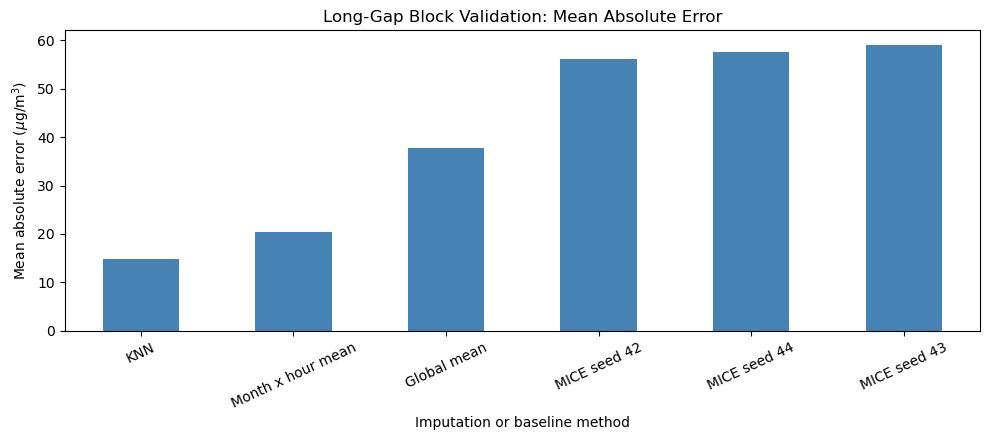

In [151]:
fig, ax = plt.subplots(figsize=(10, 4.5))
block_scores["MAE (ug/m^3)"].sort_values().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Long-Gap Block Validation: Mean Absolute Error")
ax.set_xlabel("Imputation or baseline method")
ax.set_ylabel(r"Mean absolute error ($\mu$g/m$^3$)")
ax.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
plt.show()

**Observation:** KNN has the lowest block-validation MAE (14.81 ug/m^3), followed by the month-by-hour mean (20.39 ug/m^3). All three MICE seeds and the global mean perform worse on these outage-like blocks, so KNN is the strongest tested long-gap estimator here.

### 5.1 Inspect estimated distributions

For the visual comparison, KNN and MICE are evaluated on the same long-gap hours that short-gap interpolation cannot fill. The measured distribution is shown as context, but visual smoothness is not a measure of accuracy. Use the block-validation table above to compare errors.

In [152]:
pm_short = interpolate_short_gaps(pm)
pm_knn = multivariate_pm_imputation(pm, no2, "KNN")
pm_mice = multivariate_pm_imputation(pm, no2, "MICE", seed=42)
long_gap = pm_short.isna()

imputation_summary = pd.DataFrame(
    {
        "observed_only": pm.dropna(),
        "short_gap_treatment": pm_short,
        "all_missing_filled_KNN": pm_knn,
        "all_missing_filled_MICE": pm_mice,
    }
).agg(["count", "mean", "std", "skew", "kurt"]).T
print("Summary statistics for observed and estimated series:")
display(imputation_summary.round(3))
print("Long-gap hours available for the shared KDE comparison:", int(long_gap.sum()))

Summary statistics for observed and estimated series:


,count,mean,std,skew,kurt
observed_only,5910.0,59.431,62.188,3.641,24.633
short_gap_treatment,6040.0,60.250,66.458,4.409,35.823
all_missing_filled_KNN,6600.0,59.070,60.236,3.688,25.489
all_missing_filled_MICE,6600.0,58.859,62.126,3.293,22.242


Long-gap hours available for the shared KDE comparison: 560


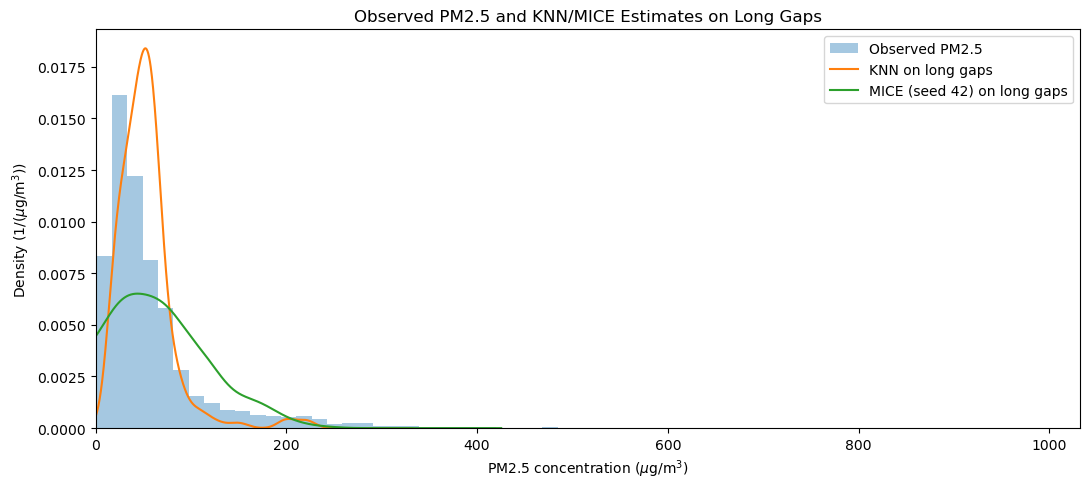

In [153]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(pm.dropna(), bins=60, density=True, alpha=0.4, label="Observed PM2.5")
for label, estimate in [("KNN", pm_knn), ("MICE (seed 42)", pm_mice)]:
    values = estimate.loc[long_gap].dropna()
    if len(values) > 1:
        values.plot(kind="kde", ax=ax, label=f"{label} on long gaps")
ax.set_xlim(left=0)
ax.set_xlabel(r"PM2.5 concentration ($\mu$g/m$^3$)")
ax.set_ylabel(r"Density (1/($\mu$g/m$^3$))")
ax.set_title("Observed PM2.5 and KNN/MICE Estimates on Long Gaps")
ax.legend()
fig.tight_layout()
plt.show()

**Observation:** KNN reduces the observed PM2.5 standard deviation from 62.2 to 60.2 ug/m^3, while MICE gives 62.1 ug/m^3. Estimates on the same long-gap hours are directly comparable, but both methods can smooth away pollution episodes.


## 6. Create and check the daily pollution dataset

The daily means use the observed hourly values plus interpolation of internal gaps of six hours or less. Longer gaps are not filled in the exported file. `pm25_hours` counts the real (non-imputed) PM2.5 hours on each date, so weakly supported days can be identified. Exact-zero NO2 readings are treated as likely sensor-floor values and left out of the daily NO2 mean only; the raw series is unchanged. Four dates have no measurements for either pollutant, so their daily values stay empty. All 275 dates from 1 March to 30 November are kept, and 30 November now uses all 24 hours.

In [154]:
no2_zero_times = no2.index[no2.eq(0)]
no2_for_daily = no2.mask(no2.eq(0))

study_start = pd.Timestamp("2025-03-01")
study_end = pd.Timestamp("2025-11-30")
study_start_date = "2025-03-01"
study_end_date = "2025-11-30"
pm_daily_hourly = interpolate_short_gaps(pm)
no2_daily_hourly = interpolate_short_gaps(no2_for_daily)

pm_daily = pm_daily_hourly.loc[study_start_date:study_end_date].resample("D").mean()
no2_daily = no2_daily_hourly.loc[study_start_date:study_end_date].resample("D").mean()
pm25_hours = pm.loc[study_start_date:study_end_date].resample("D").count().astype("int64")

In [155]:
daily = pd.DataFrame(
    {
        "date": pm_daily.index,
        "pm25": pm_daily.to_numpy(),
        "no2": no2_daily.reindex(pm_daily.index).to_numpy(),
        "pm25_hours": pm25_hours.to_numpy(),
    }
)
daily["pm_no2_ratio"] = daily["pm25"] / daily["no2"]
daily = daily[["date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"]]

print("Daily dataset shape:", daily.shape)
display(daily.head())
display(daily.tail())

Daily dataset shape: (275, 5)


,date,pm25,no2,pm25_hours,pm_no2_ratio
0,2025-03-01,51.842105,32.136842,19,1.613167
1,2025-03-02,38.208333,26.324167,24,1.451455
2,2025-03-03,56.916667,45.537500,24,1.249886
3,2025-03-04,45.916667,25.720833,24,1.785194
4,2025-03-05,27.333333,23.583333,24,1.159011


,date,pm25,no2,pm25_hours,pm_no2_ratio
270,2025-11-26,138.595833,27.304167,24,5.075996
271,2025-11-27,176.250000,39.834583,24,4.424547
272,2025-11-28,161.900000,38.254167,24,4.232219
273,2025-11-29,119.383333,39.737500,24,3.004299
274,2025-11-30,123.495833,33.608333,24,3.674560


### 6.1 Check daily coverage and missing values

Before saving, inspect the daily table, missing values by column, and the number of real PM2.5 observations per day. The four expected full-outage dates are the only dates allowed to have missing primary aggregation values (`pm25`, `no2`, and `pm_no2_ratio`).

In [156]:
expected_outage_dates = pd.to_datetime(
    ["2025-04-10", "2025-05-26", "2025-06-02", "2025-06-03"]
)

print("Missing values by column:")
print(daily.isna().sum())
print("Real PM2.5 hours per day:")
display(daily["pm25_hours"].describe().to_frame())
print("Days with no PM2.5 measurement:")
display(daily.loc[daily["pm25"].isna(), ["date", "pm25", "no2", "pm25_hours"]])

Missing values by column:
date            0
pm25            4
no2             4
pm25_hours      0
pm_no2_ratio    4
dtype: int64
Real PM2.5 hours per day:


,pm25_hours
count,275.000000
mean,21.472727
std,5.202661
min,0.000000
25%,22.000000
50%,24.000000
75%,24.000000
max,24.000000


Days with no PM2.5 measurement:


,date,pm25,no2,pm25_hours
40,2025-04-10,NaN,NaN,0
86,2025-05-26,NaN,NaN,0
93,2025-06-02,NaN,NaN,0
94,2025-06-03,NaN,NaN,0


In [157]:
expected_columns = ["date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"]
assert len(daily) == 275
assert daily["date"].min() == study_start and daily["date"].max() == study_end
assert daily.columns.tolist() == expected_columns
assert daily["pm25_hours"].between(0, 24).all()
assert daily["pm25_hours"].iloc[-1] == 24
assert daily["pm25_hours"].sum() == 5_905
assert (daily["pm25_hours"] < 12).sum() == 18
assert np.isclose(daily["pm25"].iloc[-1], 123.5, atol=0.1)
assert np.isclose(daily["no2"].iloc[-1], 33.6, atol=0.1)

for column in ["pm25", "no2", "pm_no2_ratio"]:
    null_dates = pd.to_datetime(daily.loc[daily[column].isna(), "date"]).tolist()
    assert null_dates == list(expected_outage_dates), f"Unexpected missing dates in {column}: {null_dates}"

assert daily.loc[daily["pm25"].notna(), "pm25"].ge(0).all()
assert daily.loc[daily["no2"].notna(), "no2"].gt(0).all()
assert daily.loc[daily["pm_no2_ratio"].notna(), "pm_no2_ratio"].ge(0).all()
print("Daily data checks passed.")

Daily data checks passed.


In [158]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
daily.to_csv(DAILY_PATH, index=False, date_format="%Y-%m-%d")
print("Saved daily data to:", DAILY_PATH)

Saved daily data to: c:\Users\YASHVI PATEL\Documents\Study Only\EDA\EDA-PROJECT\EDA-Group-Project\data\processed\pollution_daily.csv


### 6.2 Verify the saved file

Read the exported CSV back from disk and check its shape, columns, date bounds, and missing-value counts. This catches problems in the deliverable itself, rather than only testing the in-memory DataFrame.

In [159]:
daily_check = pd.read_csv(DAILY_PATH, parse_dates=["date"])
print("Saved file shape:", daily_check.shape)
print("Saved file columns:", daily_check.columns.tolist())
print("Saved file date range:", daily_check["date"].min(), "to", daily_check["date"].max())
print("Saved file null counts:")
print(daily_check.isna().sum())
display(daily_check.head())

Saved file shape: (275, 5)
Saved file columns: ['date', 'pm25', 'no2', 'pm25_hours', 'pm_no2_ratio']
Saved file date range: 2025-03-01 00:00:00 to 2025-11-30 00:00:00
Saved file null counts:
date            0
pm25            4
no2             4
pm25_hours      0
pm_no2_ratio    4
dtype: int64


,date,pm25,no2,pm25_hours,pm_no2_ratio
0,2025-03-01,51.842105,32.136842,19,1.613167
1,2025-03-02,38.208333,26.324167,24,1.451455
2,2025-03-03,56.916667,45.537500,24,1.249886
3,2025-03-04,45.916667,25.720833,24,1.785194
4,2025-03-05,27.333333,23.583333,24,1.159011


In [160]:
assert daily_check.shape == (275, 5)
assert daily_check.columns.tolist() == ["date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"]
assert daily_check["date"].min() == study_start
assert daily_check["date"].max() == study_end
assert daily_check[["pm25", "no2", "pm_no2_ratio"]].isna().sum().to_dict() == {
    "pm25": 4,
    "no2": 4,
    "pm_no2_ratio": 4,
}
assert daily_check["pm25_hours"].between(0, 24).all()
assert daily_check["pm25_hours"].iloc[-1] == 24
assert daily_check["pm25_hours"].sum() == 5_905
assert (daily_check["pm25_hours"] < 12).sum() == 18
print("Saved CSV checks passed.")

Saved CSV checks passed.


## 7. Outlier identification and treatment choices

IQR fences and an absolute z-score greater than 3 flag unusually high observations by different definitions. Because PM2.5 is strongly right-skewed, the mean and standard deviation are affected by the high-concentration tail. These rules are screening tools, not automatic evidence of faulty sensors.

The October 21 maximum follows Diwali on October 20. Measurements before the peak are missing for several hours, but available readings from 06:00 through 09:00 show a consecutive elevated peak and decay. The event context and observed pattern support retaining this measured peak rather than clipping it. Capping and winsorization are sensitivity comparisons only; the raw measurements remain unchanged.

In [161]:
pm_observed = pm.dropna()
q1, q3 = pm_observed.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

z_scores = (pm_observed - pm_observed.mean()) / pm_observed.std(ddof=1)
iqr_outliers = pm_observed[(pm_observed < lower_fence) | (pm_observed > upper_fence)]
z_outliers = pm_observed[z_scores.abs() > 3]

print("IQR lower fence:", round(lower_fence, 3))
print("IQR upper fence:", round(upper_fence, 3), "ug/m^3")
print("IQR outlier hours:", len(iqr_outliers))
print("Z-score outlier hours (|z| > 3):", len(z_outliers))
print("PM2.5 skewness:", round(pm_observed.skew(), 3))

IQR lower fence: -44.675
IQR upper fence: 137.125 ug/m^3
IQR outlier hours: 510
Z-score outlier hours (|z| > 3): 126
PM2.5 skewness: 3.641


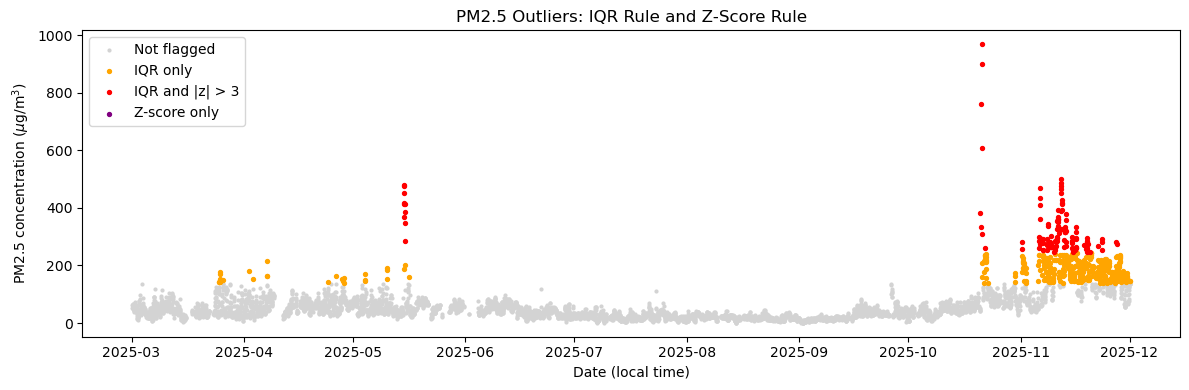

time,3,4,5,6,7,8,9,10,11,12
IQR-flagged hours,7,11,19,0,0,0,0,30,441,2


In [162]:
flag_iqr = pm_observed > upper_fence
flag_z = z_scores.abs() > 3
fig, ax = plt.subplots(figsize=(12, 4))
normal = ~(flag_iqr | flag_z)
ax.scatter(pm_observed.index[normal], pm_observed[normal], s=4, color="lightgray", label="Not flagged")
ax.scatter(pm_observed.index[flag_iqr & ~flag_z], pm_observed[flag_iqr & ~flag_z], s=8, color="orange", label="IQR only")
ax.scatter(pm_observed.index[flag_iqr & flag_z], pm_observed[flag_iqr & flag_z], s=8, color="red", label="IQR and |z| > 3")
ax.scatter(pm_observed.index[flag_z & ~flag_iqr], pm_observed[flag_z & ~flag_iqr], s=8, color="purple", label="Z-score only")
ax.set_title("PM2.5 Outliers: IQR Rule and Z-Score Rule")
ax.set_xlabel("Date (local time)")
ax.set_ylabel(r"PM2.5 concentration ($\mu$g/m$^3$)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
display(flag_iqr.groupby(pm_observed.index.month).sum().rename("IQR-flagged hours").to_frame().T)

**Observation:** About 92% of the IQR-flagged hours occur in October and November, including 441 in November; none occur from June through September. Their concentration in the smoke and Diwali season is a reason to investigate context rather than automatically call them sensor errors.

In [163]:
peak_time = pm_observed.idxmax()
pre_peak = pm.loc["2025-10-21 00:00:00"]
peak_period = pm.loc["2025-10-21 06:00:00":"2025-10-21 09:00:00"]

print("Highest PM2.5 reading:", pm_observed.max(), "ug/m^3 at", peak_time)
print("Last available pre-peak value at midnight:", pre_peak)
print("Hours from 01:00 to 05:00 are missing; available post-peak values:")
display(peak_period.to_frame("PM2.5 (ug/m^3)"))

Highest PM2.5 reading: 968.0 ug/m^3 at 2025-10-21 06:00:00
Last available pre-peak value at midnight: 760.0
Hours from 01:00 to 05:00 are missing; available post-peak values:


,PM2.5 (ug/m^3)
time,
2025-10-21 06:00:00,968.0
2025-10-21 07:00:00,899.0
2025-10-21 08:00:00,608.0
2025-10-21 09:00:00,311.0


In [164]:
no2_zero_rows = no2_raw.loc[
    no2_raw["value"].eq(0), ["time", "value", "unit", "sensor_id"]
]
print("Exact-zero NO2 readings flagged as possible sensor-floor anomalies:")
display(no2_zero_rows)
print("These readings remain in the raw series; only the daily-analysis copy masks them.")

Exact-zero NO2 readings flagged as possible sensor-floor anomalies:


,time,value,unit,sensor_id
2449,2025-06-24 15:00:00,0.0,ppb,12235309
3582,2025-08-16 10:00:00,0.0,ppb,12235309
4892,2025-10-13 10:00:00,0.0,ppb,12235309


These readings remain in the raw series; only the daily-analysis copy masks them.


In [165]:
no2_observed = no2.dropna()
q1_no2, q3_no2 = no2_observed.quantile([0.25, 0.75])
upper_fence_no2 = q3_no2 + 1.5 * (q3_no2 - q1_no2)
no2_z_scores = (no2_observed - no2_observed.mean()) / no2_observed.std(ddof=1)
print(
    "NO2 skew:", round(no2_observed.skew(), 2),
    "| IQR upper fence:", round(upper_fence_no2, 1), "ppb",
    "| IQR flags:", int((no2_observed > upper_fence_no2).sum()),
    "| |Z| > 3 flags:", int(no2_z_scores.abs().gt(3).sum()),
)

NO2 skew: 1.54 | IQR upper fence: 64.6 ppb | IQR flags: 252 | |Z| > 3 flags: 91


**Observation:** NO2 is less skewed than PM2.5 (skewness 1.54). The IQR upper fence of 64.6 ppb flags 252 hours and |z| > 3 flags 91. The three exact-zero readings (24 Jun 15:00, 16 Aug 10:00, 13 Oct 10:00) are treated separately as possible sensor-floor values.

Daily dates flagged by either multivariate method: 14


,pm25,no2,pm_no2_ratio,mahalanobis_d2,mahalanobis,isolation_forest
date,,,,,,
2025-10-21,399.91,12.41,32.23,78.83,True,True
2025-11-12,298.92,38.91,7.68,21.96,True,True
2025-11-13,271.17,41.56,6.52,17.09,True,True
2025-11-11,257.33,42.47,6.06,14.94,True,True
2025-11-10,237.46,41.22,5.76,12.01,True,True
2025-11-19,216.46,25.56,8.47,9.68,False,True
2025-11-20,195.12,22.42,8.70,7.74,False,True
2025-10-22,174.52,18.29,9.54,6.78,False,True
2025-04-07,86.88,58.85,1.48,9.58,False,True


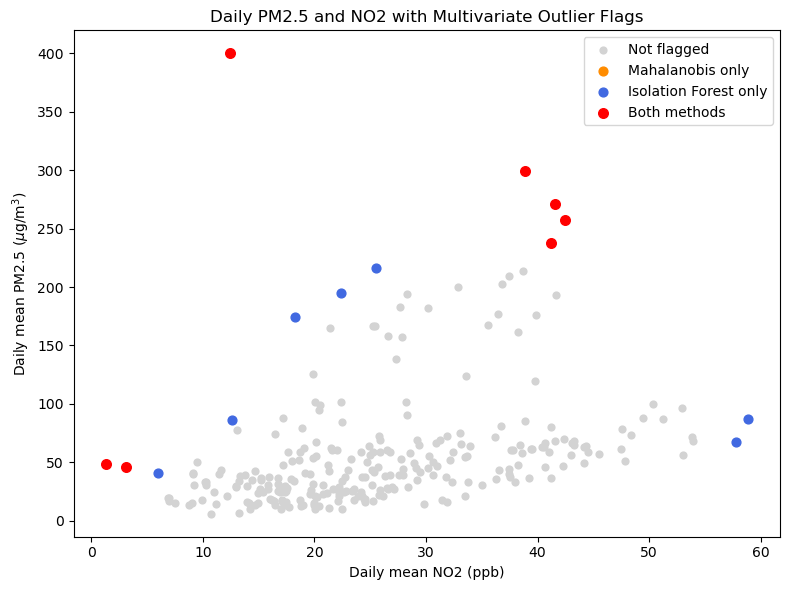

In [166]:
X = daily.set_index("date")[["pm25", "no2", "pm_no2_ratio"]].dropna()
Z = (X - X.mean()) / X.std(ddof=1)
difference = Z.to_numpy() - Z.to_numpy().mean(axis=0)
covariance = np.cov(Z.to_numpy(), rowvar=False)
mahalanobis_squared = np.einsum(
    "ij,jk,ik->i", difference, np.linalg.inv(covariance), difference
)
mahalanobis_flag = mahalanobis_squared > stats.chi2.ppf(0.99, df=3)
isolation_flag = IsolationForest(
    contamination=0.05, random_state=RANDOM_STATE
).fit_predict(Z) == -1
multivariate_flags = X.assign(
    mahalanobis_d2=mahalanobis_squared,
    mahalanobis=mahalanobis_flag,
    isolation_forest=isolation_flag,
)
flagged_days = multivariate_flags.loc[
    multivariate_flags["mahalanobis"] | multivariate_flags["isolation_forest"]
].sort_values("pm25", ascending=False)
print("Daily dates flagged by either multivariate method:", len(flagged_days))
display(flagged_days.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X["no2"], X["pm25"], s=24, color="lightgray", label="Not flagged")
ax.scatter(
    X.loc[mahalanobis_flag & ~isolation_flag, "no2"],
    X.loc[mahalanobis_flag & ~isolation_flag, "pm25"],
    s=40, color="darkorange", label="Mahalanobis only",
)
ax.scatter(
    X.loc[isolation_flag & ~mahalanobis_flag, "no2"],
    X.loc[isolation_flag & ~mahalanobis_flag, "pm25"],
    s=40, color="royalblue", label="Isolation Forest only",
)
ax.scatter(
    X.loc[mahalanobis_flag & isolation_flag, "no2"],
    X.loc[mahalanobis_flag & isolation_flag, "pm25"],
    s=48, color="red", label="Both methods",
)
ax.set_title("Daily PM2.5 and NO2 with Multivariate Outlier Flags")
ax.set_xlabel("Daily mean NO2 (ppb)")
ax.set_ylabel(r"Daily mean PM2.5 ($\mu$g/m$^3$)")
ax.legend()
fig.tight_layout()
plt.show()

**Observation:** Both methods flag 7 days: 21 Oct (Diwali), 10–13 Nov and 24–25 Jun. Isolation Forest alone adds 7 more, including 19–20 Nov and 22 Oct. On 24–25 Jun both methods flag very low NO2 (3.1 and 1.3 ppb), which pushes the PM2.5/NO2 ratio up to 14.9 and 38.3 while PM2.5 is only 46–49 µg/m³. These are statistical flags, not proof of faulty measurements.


In [167]:
cap_iqr = pm_observed.clip(lower=lower_fence, upper=upper_fence)
p05, p95 = pm_observed.quantile([0.05, 0.95])
winsor_5pct = pm_observed.clip(lower=p05, upper=p95)
log_pm = np.log1p(pm_observed)

outlier_comparison = pd.DataFrame(
    {
        "raw": [pm_observed.min(), pm_observed.max(), pm_observed.mean(), pm_observed.std(), pm_observed.skew(), pm_observed.kurt()],
        "IQR capped": [cap_iqr.min(), cap_iqr.max(), cap_iqr.mean(), cap_iqr.std(), cap_iqr.skew(), cap_iqr.kurt()],
        "5/95% winsorized": [winsor_5pct.min(), winsor_5pct.max(), winsor_5pct.mean(), winsor_5pct.std(), winsor_5pct.skew(), winsor_5pct.kurt()],
        "log1p(raw)": [log_pm.min(), log_pm.max(), log_pm.mean(), log_pm.std(), log_pm.skew(), log_pm.kurt()],
    },
    index=["minimum", "maximum", "mean", "standard deviation", "skewness", "kurtosis"],
).T
print("Diagnostic comparison only; the daily file remains uncapped and untransformed:")
display(outlier_comparison.round(3))

Diagnostic comparison only; the daily file remains uncapped and untransformed:


,minimum,maximum,mean,standard deviation,skewness,kurtosis
raw,1.000,968.000,59.431,62.188,3.641,24.633
IQR capped,1.000,137.125,52.150,37.442,1.060,0.149
5/95% winsorized,10.890,188.550,55.792,46.095,1.610,1.932
log1p(raw),0.693,6.876,3.755,0.816,0.120,0.296


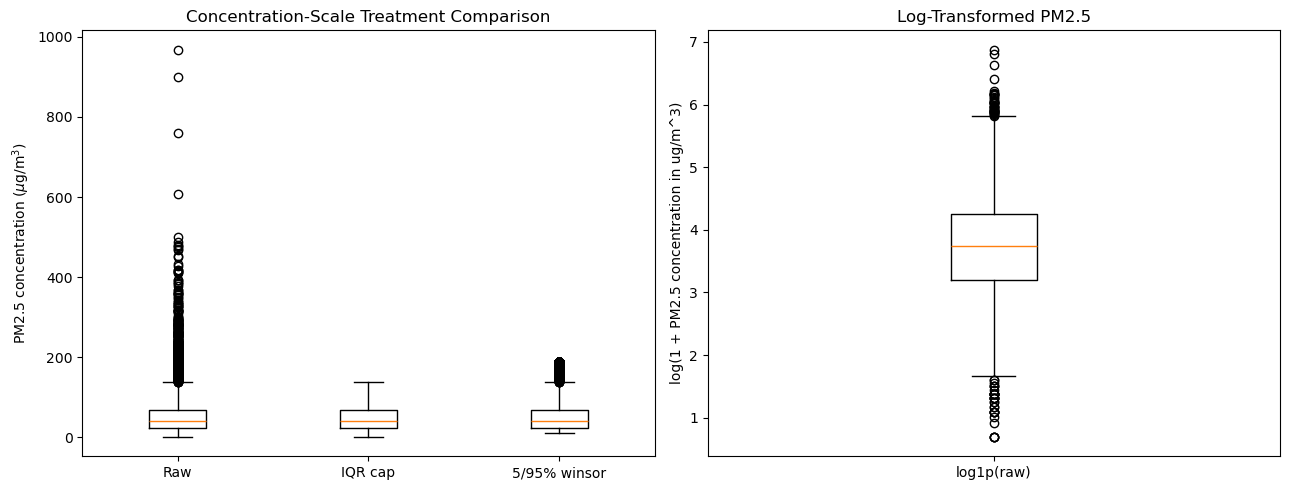

In [168]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].boxplot(
    [pm_observed, cap_iqr, winsor_5pct],
    tick_labels=["Raw", "IQR cap", "5/95% winsor"],
)
axes[0].set_ylabel(r"PM2.5 concentration ($\mu$g/m$^3$)")
axes[0].set_title("Concentration-Scale Treatment Comparison")

axes[1].boxplot([log_pm], tick_labels=["log1p(raw)"])
axes[1].set_ylabel("log(1 + PM2.5 concentration in ug/m^3)")
axes[1].set_title("Log-Transformed PM2.5")
fig.tight_layout()
plt.show()

**Observation:** The raw distribution has skewness 3.64 and kurtosis 24.63; log(1 + PM2.5) reduces them to 0.12 and 0.30. IQR capping at 137.125 ug/m^3 would clip the observed Diwali-period peak, so the raw values are retained.


### 7.1 Final checks

The final assertions verify the expected IQR and z-score counts, the retained Diwali-period maximum and its observed subsequent readings, all three NO2 zero-value timestamps, and constraints on the exported daily dataset. The outlier flags do not delete, cap, or overwrite hourly source measurements.

In [169]:
expected_no2_zero_times = pd.to_datetime(
    ["2025-06-24 15:00:00", "2025-08-16 10:00:00", "2025-10-13 10:00:00"]
)

assert np.isclose(upper_fence, 137.125)
assert len(iqr_outliers) == 510
assert len(z_outliers) == 126
assert pm_observed.max() == 968
assert peak_time == pd.Timestamp("2025-10-21 06:00:00")
assert pre_peak == 760
assert peak_period.tolist() == [968, 899, 608, 311]
assert no2_zero_rows["time"].tolist() == list(expected_no2_zero_times)
assert daily_check.shape == (275, 5)
assert daily_check["pm25"].isna().sum() == 4
assert daily_check["no2"].isna().sum() == 4
assert daily_check["pm_no2_ratio"].isna().sum() == 4
print("Final data and outlier checks passed.")

Final data and outlier checks passed.


## Summary and Conclusions: Data Cleaning and Outlier Analysis

### What was done
- **Loading and hourly calendar:** The hourly PM2.5 and NO2 files were loaded and extended to a full hourly calendar of 6,600 hours (1 Mar 05:00 to 1 Dec 04:00). PM2.5 is missing 690 hours (10.5%) and NO2 is missing 615 hours (9.3%). Each pollutant comes from one sensor, and there are no duplicate timestamps.
- **Missing values:** PM2.5 has 94 gaps and the longest is 60 hours. The share of missing hours changes by month (the chi-square p-value is very small), so the data is not missing purely at random. 574 of the 690 missing PM2.5 hours are also missing NO2, which suggests the station was often offline.
- **Outliers:** The IQR rule flags 510 hours and the Z-score rule flags 126, because PM2.5 is strongly right-skewed (skewness 3.64). After a log(1 + PM2.5) transform the skewness drops to 0.12.

### Decisions
1. **Short gaps (6 hours or less)** are filled by time interpolation, because PM2.5 changes smoothly over a few hours.
2. **Long gaps (more than 6 hours):** To compare fill methods, 30 blocks of 20 hours were hidden and each method was scored on how well it recovered them.

   | Method | MAE (µg/m³) | RMSE (µg/m³) |
   |---|---|---|
   | KNN | 14.81 | 23.24 |
   | Month-by-hour average | 20.39 | 31.75 |
   | Global mean | 37.70 | 54.82 |
   | MICE (3 seeds) | 56.14 / 59.13 / 57.66 | 73.20 / 76.38 / 74.97 |

   KNN was the best of these, but its values are still estimates. The daily file does not use them, so long gaps stay empty there.
3. **Outliers are kept.** The highest reading is 968 µg/m³ on 21 Oct at 06:00, the morning after Diwali. It rises and falls over several hours, so it is a real smoke event and not a sensor error. About 92% of IQR-flagged hours fall in October and November.
4. **Daily dataset:** It has 275 rows. Four days have no data (10 Apr, 26 May, 2 Jun, 3 Jun) and 18 days have fewer than 12 real PM2.5 hours. Three NO2 readings of exactly 0 ppb were treated as sensor errors and excluded from the daily means.

### Limitations and open decision for modelling
- One sensor and one year of data, so results describe this station only.
- Days with no data, or with fewer than 12 real hours, are weaker evidence. The plan for the modelling stage is to leave them out of scoring and to build yesterday's value and the 7-day average from a continuous copy of the series. This rule has not been finalised.
- The modelling stage will predict log(1 + PM2.5) and convert it back to µg/m³ before scoring.